# Telco churn analysis to reduce churning

We have a data of customers and we have new customers coming and going every month. so, our revenue and market share changes. To make our position solid and increase our revenue, we have to control customer churn rate as it is one of the biggest factors which governs our revenue and market share. so, we want to find the customers who are going to churn and give them some offer to retain them. we have to well balance between false negative and false positive so as we don't spend too much giving offer to non-churn customer or loss too much as potential revenue from the churning customer in case of false negative.

## Cost asymmetry:
we assume that both false negative and false positive are serius problems. as the same customer may churn in just one month again so we can't just directly compare the future revenue from retaining customers to the cost associated with false positive. so, will compare their expected values.

## Primary metric:
we will optimize for both precision and recall and try to land on a state tilted towards the recall as in telecom industry the expected gain from retaining a customer is often greater than expacted cost of offers provided. we will go for F2 score as we can see from the cost asymmetry.

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

# EDA

In [2]:
df = pd.read_csv(r'WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.sample(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
2437,0567-GGCAC,Female,0,No,No,7,Yes,No,DSL,Yes,...,Yes,No,No,No,Month-to-month,No,Electronic check,61.40,438.9,No
6348,1025-FALIX,Female,0,No,No,26,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Credit card (automatic),69.05,1815.65,No
1819,6701-DHKWQ,Female,0,Yes,Yes,61,No,No phone service,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),51.35,3244.4,No
2141,6648-INWPS,Male,0,Yes,Yes,16,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Electronic check,20.15,341.35,No
5919,6625-IUTTT,Male,0,No,No,67,Yes,No,DSL,Yes,...,Yes,No,No,Yes,Two year,No,Bank transfer (automatic),65.55,4361.55,No


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
for i in ['MonthlyCharges', 'TotalCharges']:
    # Strip leading and trailing whitespace
    df[i] = df[i].astype(str).str.strip()

    # Replace empty strings with NaN (so pandas knows they are missing values)
    df[i] = df[i].replace('', np.nan)

    # Convert the column to float
    df[i] = df[i].astype(float)

In [5]:
df['MonthlyCharges'].isna().sum()

np.int64(0)

In [6]:
df['TotalCharges'].isna().sum()

np.int64(11)

In [7]:
df[df['TotalCharges'].isna()].replace(np.nan, 0)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,0.0,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,0.0,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,0.0,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,0.0,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,0.0,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,0.0,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,0.0,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,0.0,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,0.0,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,0.0,No


#### There are 11 customers having NaN in TotalCharges. This is because there tenure is 0. They are new customers. We will consider there TotalCharges as 0 and include these data points as they contain some important information.

In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


#### There are 25% of customers in the ranges (18.25, 35.5), and (70.35, 89.85) of MonthlyCharges and (0, 9) of tenure.

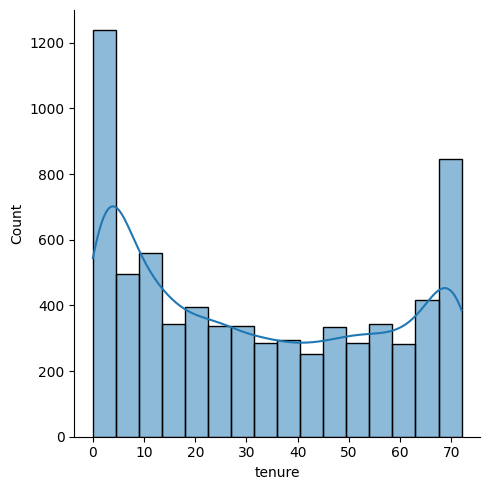

In [9]:
sns.displot(df['tenure'], kde=True)

<Axes: ylabel='tenure'>

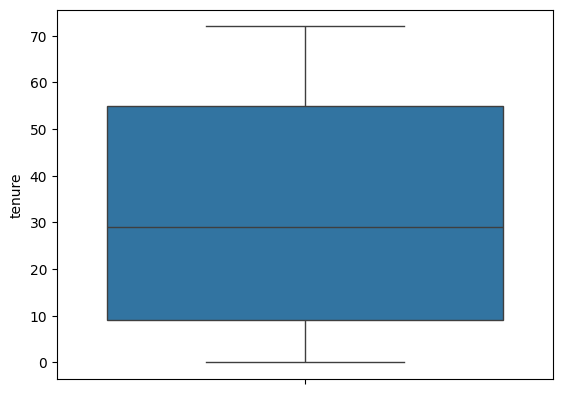

In [10]:
sns.boxplot(df['tenure'])

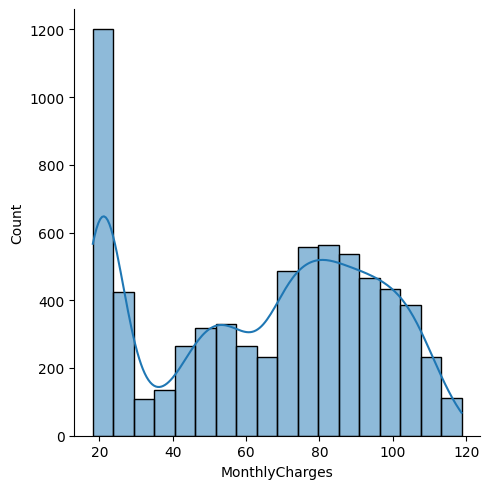

In [11]:
sns.displot(df['MonthlyCharges'], kde=True)

<Axes: ylabel='MonthlyCharges'>

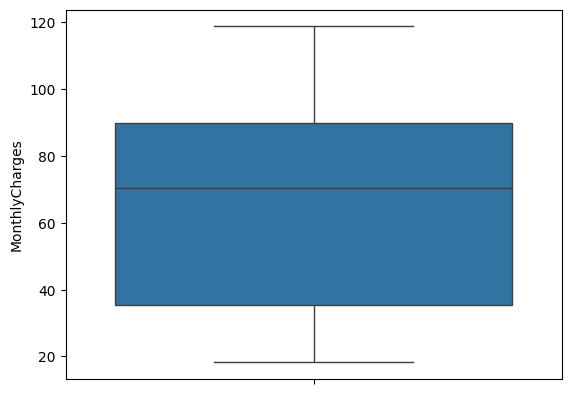

In [12]:
sns.boxplot(df['MonthlyCharges'])

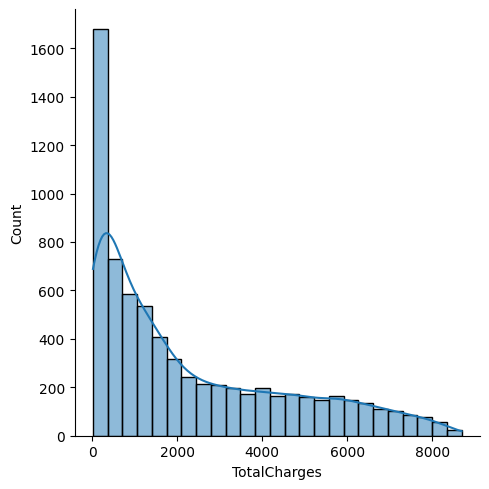

In [13]:
sns.displot(df['TotalCharges'], kde=True)

#### The plot of tenure shows that there are more low TotalCharges customers than the high TotalCharges customers.

<Axes: ylabel='TotalCharges'>

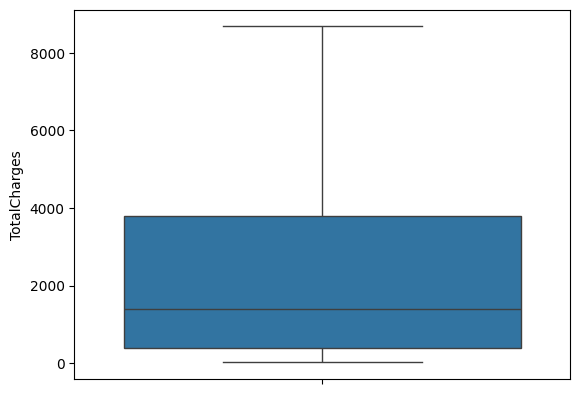

In [14]:
sns.boxplot(df['TotalCharges'])

In [15]:
# checking whether df['TotalCharges'] - df['tenure']*df['MonthlyCharges']
# Create df1 with your selected columns
df1 = df[['tenure', 'MonthlyCharges', 'TotalCharges']].copy()

# Add the new column (e.g., named 'calculated_total' or 'product')
df1['calculated_total'] = df['tenure'] * df['MonthlyCharges']

df1.corr()

,tenure,MonthlyCharges,TotalCharges,calculated_total
tenure,1.000000,0.247900,0.825880,0.826568
MonthlyCharges,0.247900,1.000000,0.651065,0.651566
TotalCharges,0.825880,0.651065,1.000000,0.999560
calculated_total,0.826568,0.651566,0.999560,1.000000


#### Resulted correlation between calculated total and TotalCharges is 0.999560. so, we can just remove TotalCharges and only use MonthlyCharges and tenure.

In [16]:
print(df.columns)

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')


In [17]:
cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'Churn']

<Axes: >

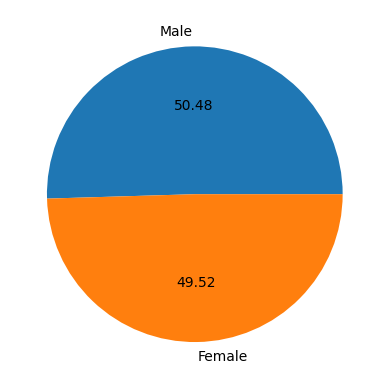

In [18]:
df[cols[0]].value_counts().plot(kind='pie', autopct='%.2f')

In [19]:
# for i in range(len(cols)):
#     print(f'sns.countplot(x=df[cols[{i}]])')

#     print(f'df[cols[{i}]].value_counts()/df[cols[{i}]].count()*100')

SeniorCitizen
0    83.785319
1    16.214681
Name: count, dtype: float64

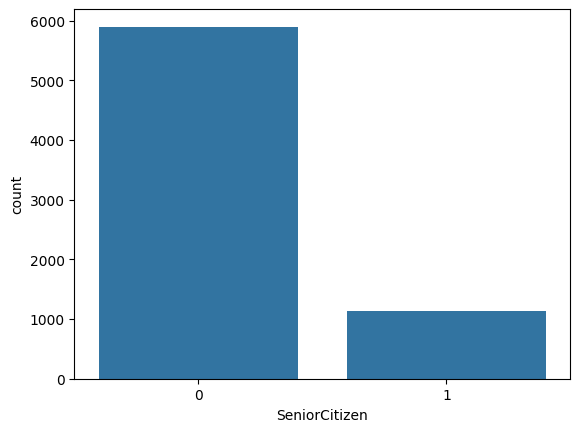

In [20]:
sns.countplot(x=df[cols[1]], color='C0')
df[cols[1]].value_counts()/df[cols[1]].count()*100

Partner
No     51.69672
Yes    48.30328
Name: count, dtype: float64

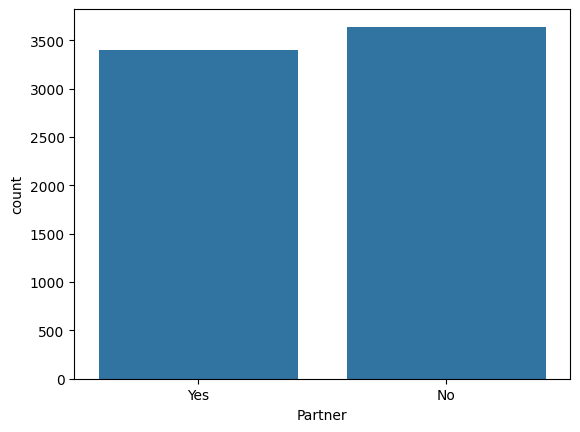

In [21]:
sns.countplot(x=df[cols[2]], color='C0')
df[cols[2]].value_counts()/df[cols[2]].count()*100

Dependents
No     70.041176
Yes    29.958824
Name: count, dtype: float64

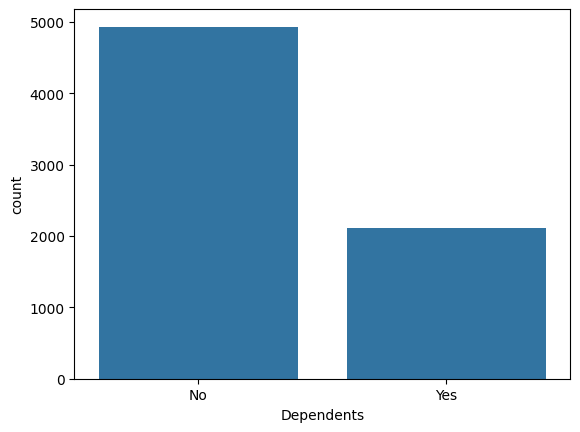

In [22]:
sns.countplot(x=df[cols[3]], color='C0')
df[cols[3]].value_counts()/df[cols[3]].count()*100

PhoneService
Yes    90.316626
No      9.683374
Name: count, dtype: float64

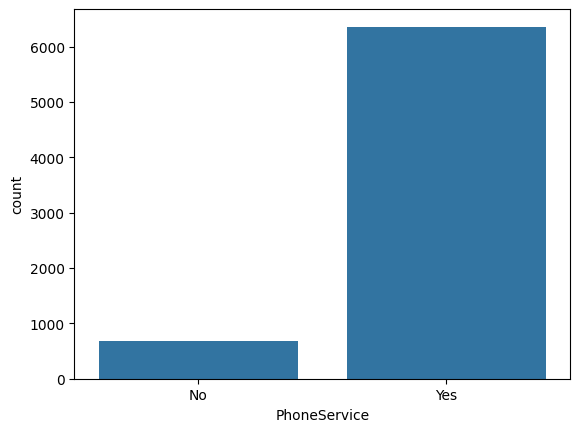

In [23]:
sns.countplot(x=df[cols[4]], color='C0')
df[cols[4]].value_counts()/df[cols[4]].count()*100

MultipleLines
No                  48.132898
Yes                 42.183729
No phone service     9.683374
Name: count, dtype: float64

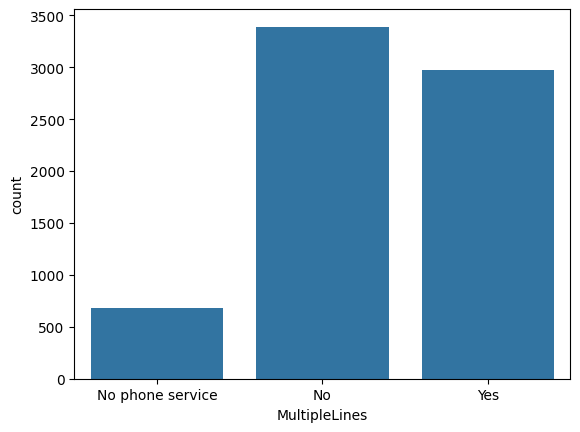

In [24]:
sns.countplot(x=df[cols[5]], color='C0')
df[cols[5]].value_counts()/df[cols[5]].count()*100

InternetService
Fiber optic    43.958540
DSL            34.374556
No             21.666903
Name: count, dtype: float64

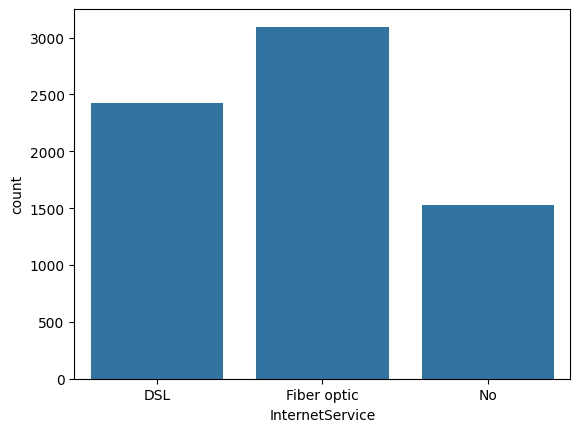

In [25]:
sns.countplot(x=df[cols[6]], color='C0')
df[cols[6]].value_counts()/df[cols[6]].count()*100

OnlineSecurity
No                     49.666335
Yes                    28.666761
No internet service    21.666903
Name: count, dtype: float64

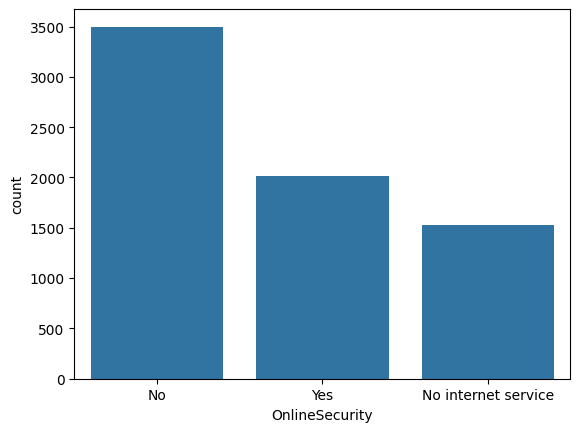

In [26]:
sns.countplot(x=df[cols[7]], color='C0')
df[cols[7]].value_counts()/df[cols[7]].count()*100

OnlineBackup
No                     43.844952
Yes                    34.488144
No internet service    21.666903
Name: count, dtype: float64

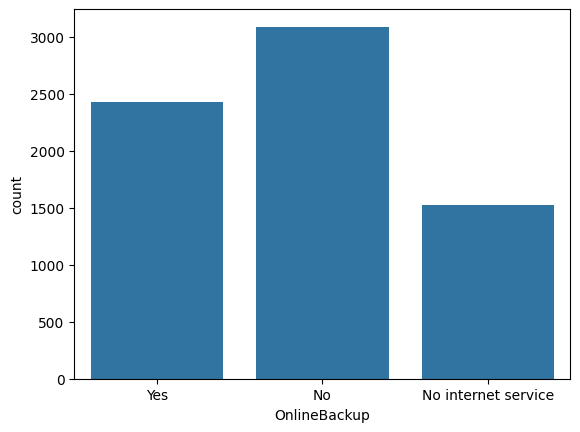

In [27]:
sns.countplot(x=df[cols[8]], color='C0')
df[cols[8]].value_counts()/df[cols[8]].count()*100

DeviceProtection
No                     43.944342
Yes                    34.388755
No internet service    21.666903
Name: count, dtype: float64

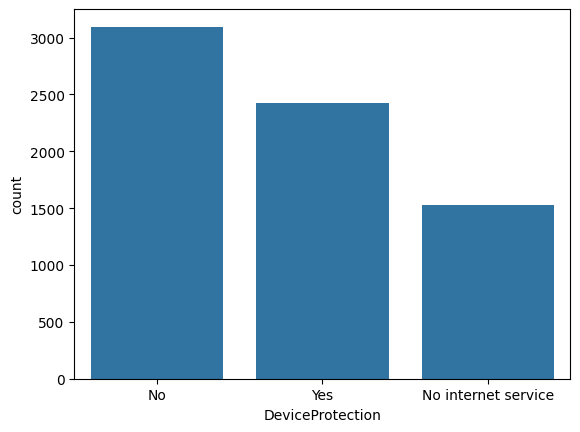

In [28]:
sns.countplot(x=df[cols[9]], color='C0')
df[cols[9]].value_counts()/df[cols[9]].count()*100

TechSupport
No                     49.311373
Yes                    29.021724
No internet service    21.666903
Name: count, dtype: float64

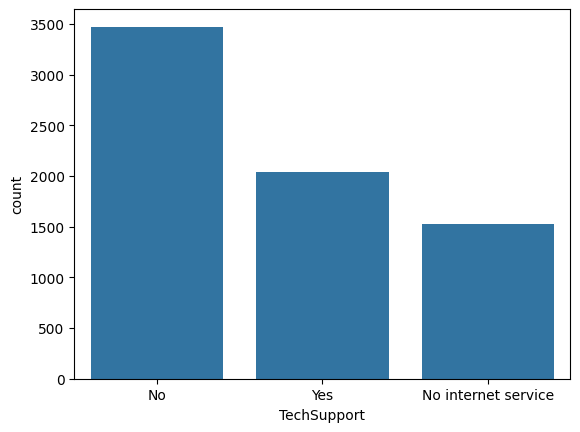

In [29]:
sns.countplot(x=df[cols[10]], color='C0')
df[cols[10]].value_counts()/df[cols[10]].count()*100

StreamingTV
No                     39.897771
Yes                    38.435326
No internet service    21.666903
Name: count, dtype: float64

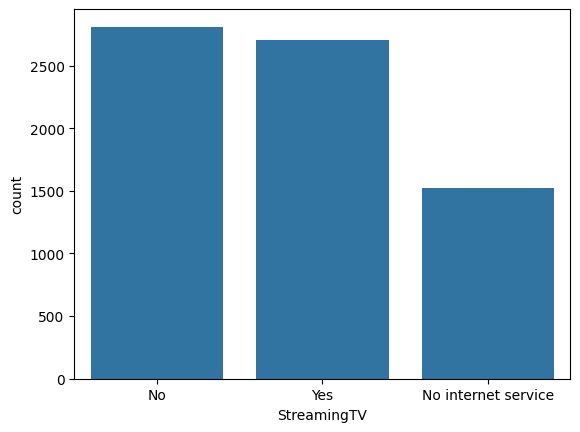

In [30]:
sns.countplot(x=df[cols[11]], color='C0')
df[cols[11]].value_counts()/df[cols[11]].count()*100

StreamingMovies
No                     39.542808
Yes                    38.790288
No internet service    21.666903
Name: count, dtype: float64

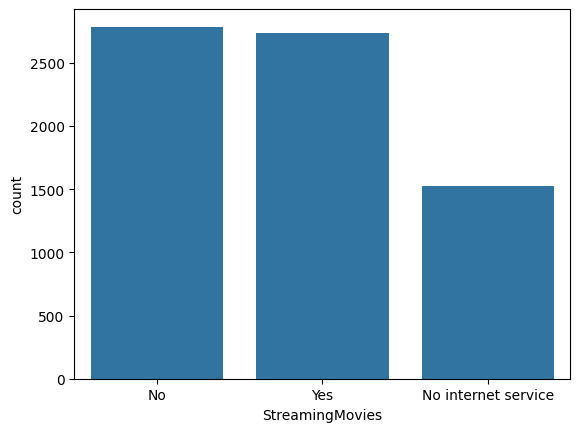

In [31]:
sns.countplot(x=df[cols[12]], color='C0')
df[cols[12]].value_counts()/df[cols[12]].count()*100

Contract
Month-to-month    55.019168
Two year          24.066449
One year          20.914383
Name: count, dtype: float64

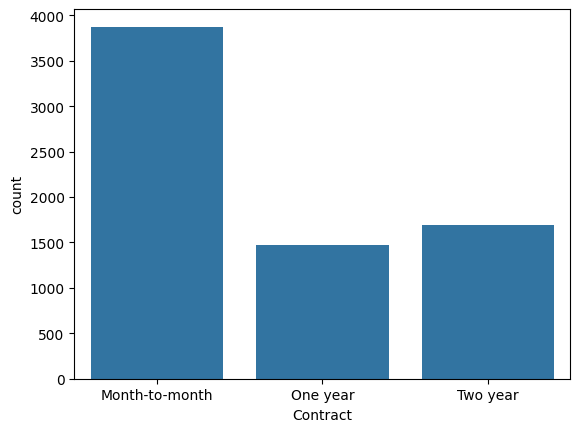

In [32]:
sns.countplot(x=df[cols[13]], color='C0')
df[cols[13]].value_counts()/df[cols[13]].count()*100

PaperlessBilling
Yes    59.221922
No     40.778078
Name: count, dtype: float64

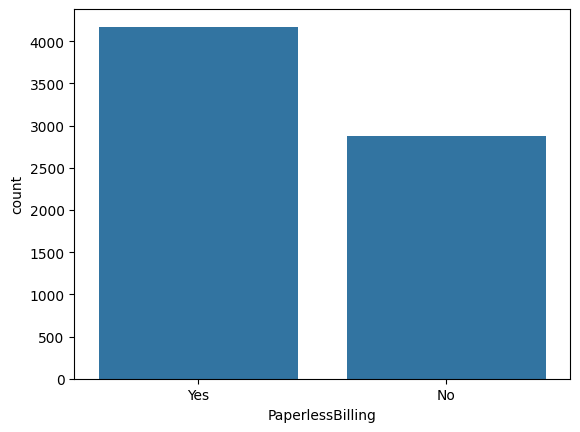

In [33]:
sns.countplot(x=df[cols[14]], color='C0')
df[cols[14]].value_counts()/df[cols[14]].count()*100

PaymentMethod
Electronic check             33.579441
Mailed check                 22.887974
Bank transfer (automatic)    21.922476
Credit card (automatic)      21.610109
Name: count, dtype: float64

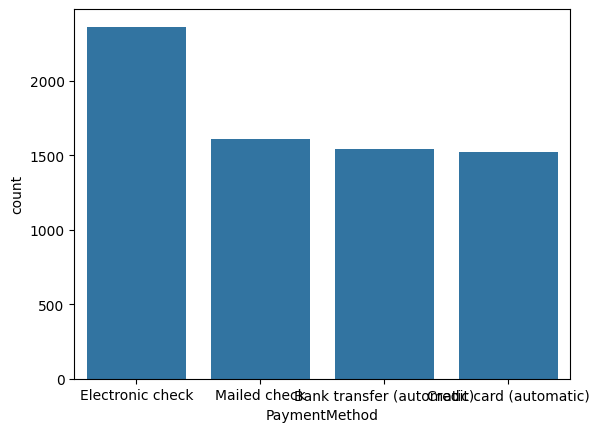

In [34]:
sns.countplot(x=df[cols[15]], color='C0')
df[cols[15]].value_counts()/df[cols[15]].count()*100

Churn
No     73.463013
Yes    26.536987
Name: count, dtype: float64

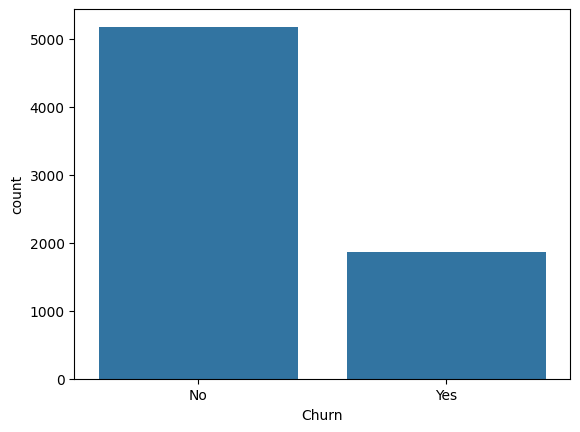

In [35]:
sns.countplot(x=df[cols[16]], color='C0')
df[cols[16]].value_counts()/df[cols[16]].count()*100

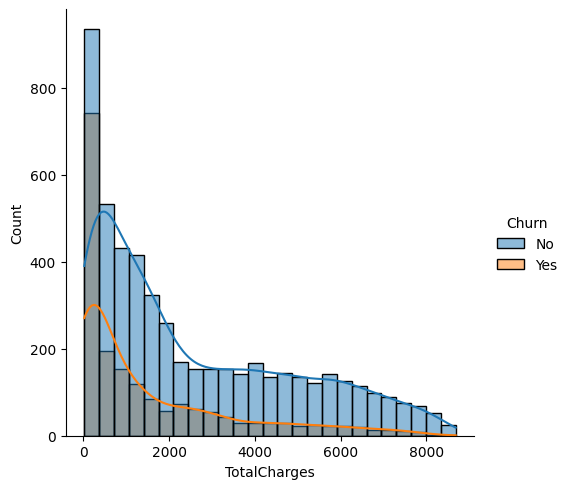

In [36]:
sns.displot(data=df, x='TotalCharges', hue='Churn', kde=True)

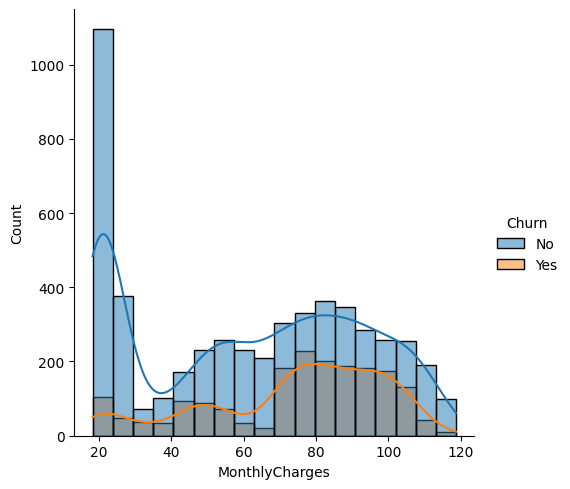

In [37]:
sns.displot(data=df, x='MonthlyCharges', hue='Churn', kde=True)

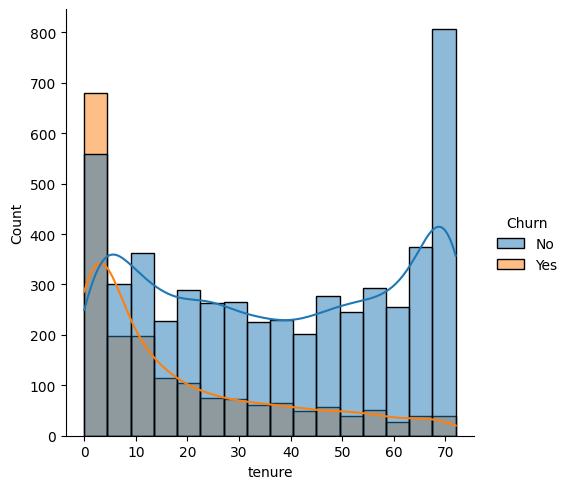

In [38]:
sns.displot(data=df, x='tenure', hue='Churn', kde=True)

In [39]:
# k = pd.crosstab(df['Churn'], df['Contract'])
# sns.heatmap(k)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


<Axes: xlabel='Contract'>

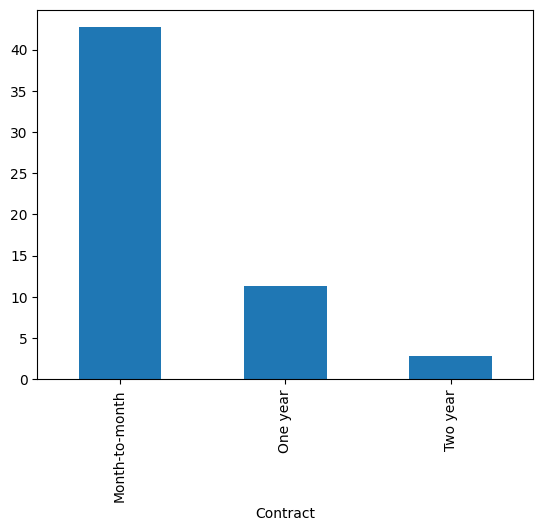

In [40]:
# Convert 'Yes'/'No' to 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Run the groupby on the numeric column
a = df.groupby('Contract')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### customers with Month-to-Month are 4 times likely to churn than the One year contract customers. and two year contract customer are very unlikely to churn.

gender
Female    26.920872
Male      26.160338
Name: Churn, dtype: float64


<Axes: xlabel='gender'>

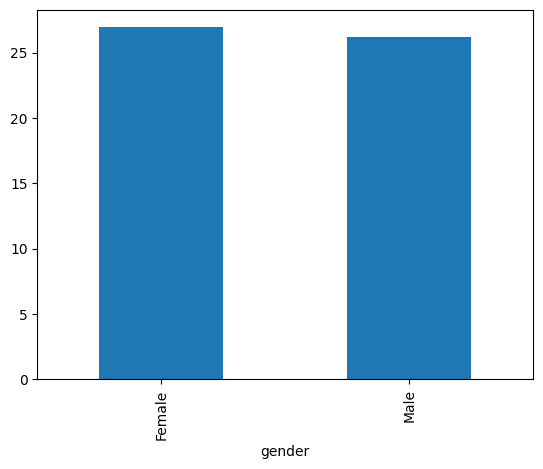

In [41]:
a = df.groupby('gender')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### As the percentage of costomer churning are in similar proportion for both genders and the proportion of both genders in the data is also similar. so, we drop the gender.

PaperlessBilling
No     16.330084
Yes    33.565092
Name: Churn, dtype: float64


<Axes: xlabel='PaperlessBilling'>

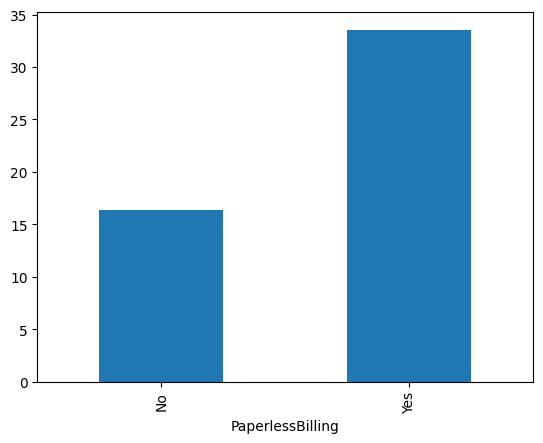

In [42]:
a = df.groupby('PaperlessBilling')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### Customers with PaperlessBilling are twice as more likely to churn than without PaperlessBilling.

StreamingMovies
No                     33.680431
No internet service     7.404980
Yes                    29.941435
Name: Churn, dtype: float64


<Axes: xlabel='StreamingMovies'>

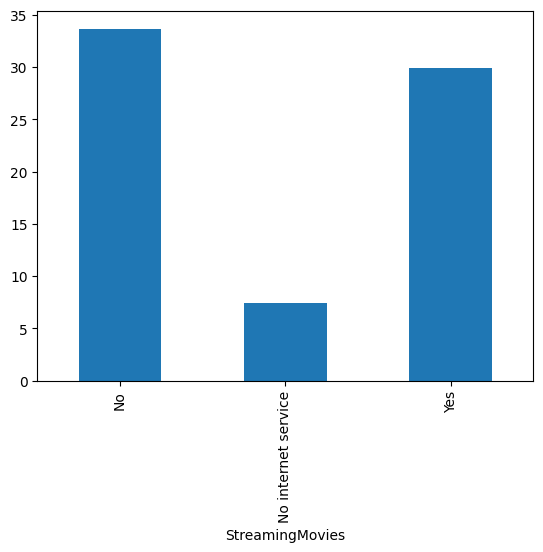

In [43]:
a = df.groupby('StreamingMovies')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### Customers Not subscribing StreamingMovies are a little bit more likely to churn than the one subscribing StreamingMovies, who are in turn 4 times more likely to churn than the customers wiht No internet service.

StreamingTV
No                     33.523132
No internet service     7.404980
Yes                    30.070188
Name: Churn, dtype: float64


<Axes: xlabel='StreamingTV'>

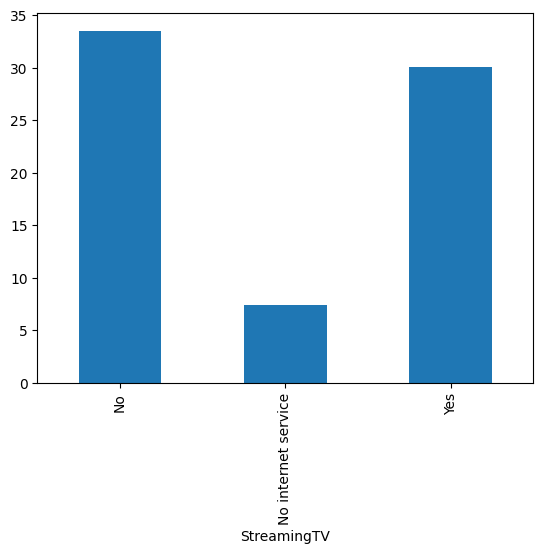

In [44]:
a = df.groupby('StreamingTV')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### same as StreamingMovies for StreamingTV.

TechSupport
No                     41.635474
No internet service     7.404980
Yes                    15.166341
Name: Churn, dtype: float64


<Axes: xlabel='TechSupport'>

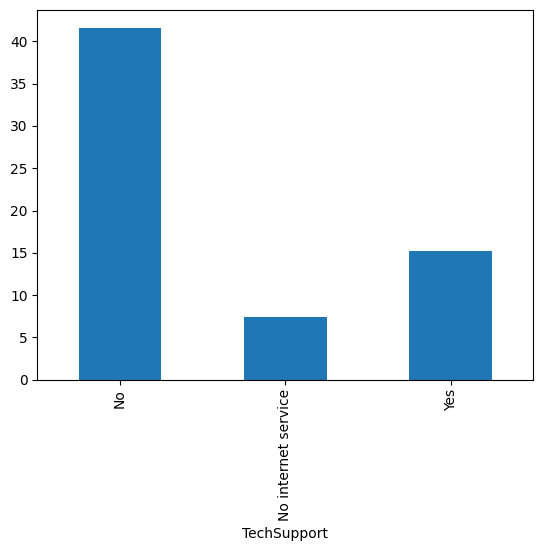

In [45]:
a = df.groupby('TechSupport')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### Customers without TechSupport are about thrice as likely to churn than the customers with TechSupport who are in turn twice as likely to churn than the ones with No internet service.

DeviceProtection
No                     39.127625
No internet service     7.404980
Yes                    22.502064
Name: Churn, dtype: float64


<Axes: xlabel='DeviceProtection'>

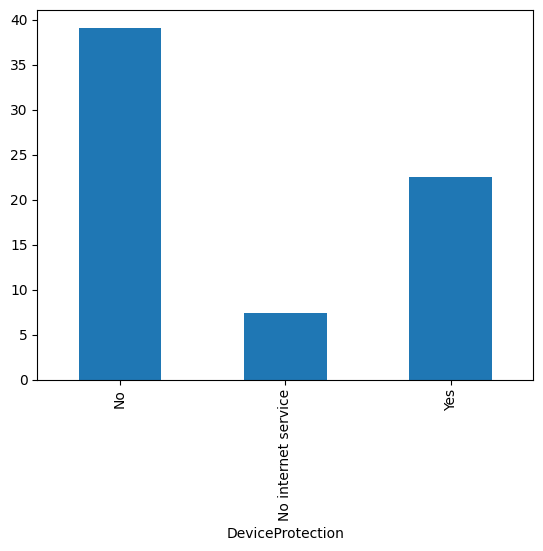

In [46]:
a = df.groupby('DeviceProtection')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### Customers without DeviceProtection are about twice as likely to churn than the customers with DeviceSupport who are in turn thrice as likely to churn than the ones with No internet service.

OnlineBackup
No                     39.928756
No internet service     7.404980
Yes                    21.531494
Name: Churn, dtype: float64


<Axes: xlabel='OnlineBackup'>

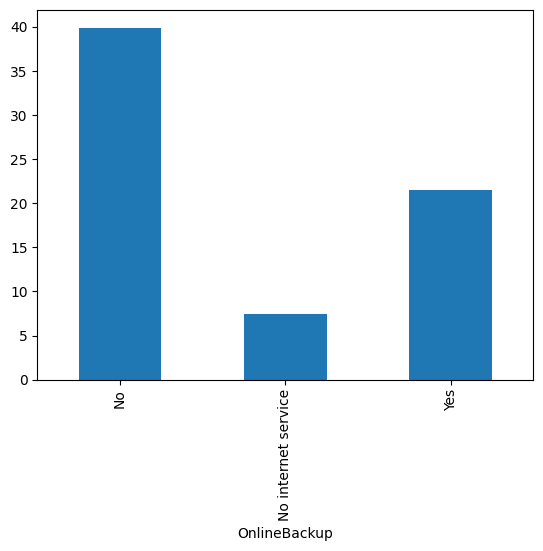

In [47]:
a = df.groupby('OnlineBackup')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### OnlineBackup is same as DeviceProtection.

OnlineSecurity
No                     41.766724
No internet service     7.404980
Yes                    14.611194
Name: Churn, dtype: float64


<Axes: xlabel='OnlineSecurity'>

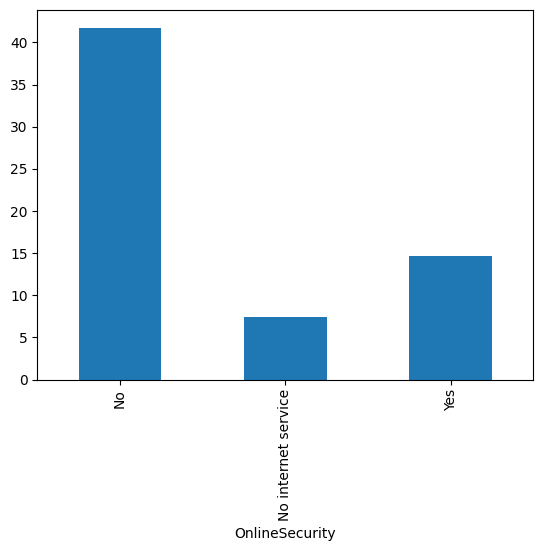

In [48]:
a = df.groupby('OnlineSecurity')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### Customers without OnlineSecurity are about twice as likely to churn than the customers with OnlineSecurity who are in turn thrice as likely to churn than the ones with No internet service.

InternetService
DSL            18.959108
Fiber optic    41.892765
No              7.404980
Name: Churn, dtype: float64


<Axes: xlabel='InternetService'>

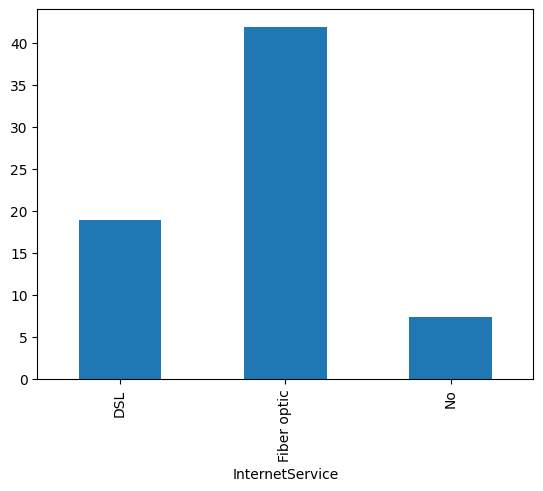

In [49]:
a = df.groupby('InternetService')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### Customers without FiberOptics InternerService are about twice as likely to churn than the customers with DSL InternetService who are in turn 2.5 times more likely to churn than the ones with No internetService.

MultipleLines
No                  25.044248
No phone service    24.926686
Yes                 28.609896
Name: Churn, dtype: float64


<Axes: xlabel='MultipleLines'>

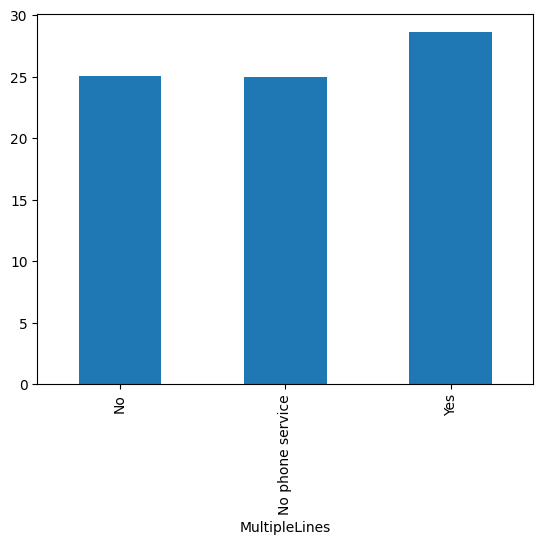

In [50]:
a = df.groupby('MultipleLines')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### For multiple lines for all categories the proportion of churning customers is about same. so, we can drop this column.

Dependents
No     31.279140
Yes    15.450237
Name: Churn, dtype: float64


<Axes: xlabel='Dependents'>

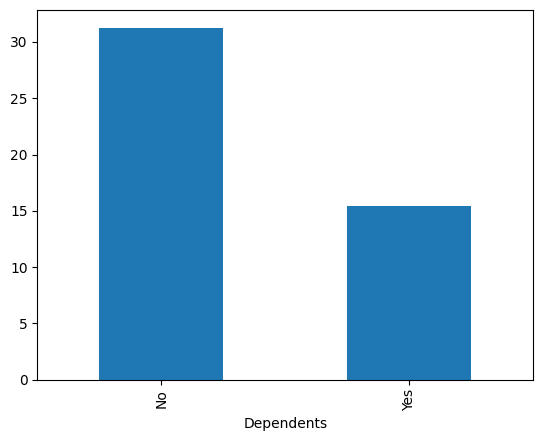

In [51]:
a = df.groupby('Dependents')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### Customers without Dependents are about twice as likely to churn than the customers with Dependents.

Partner
No     32.957979
Yes    19.664903
Name: Churn, dtype: float64


<Axes: xlabel='Partner'>

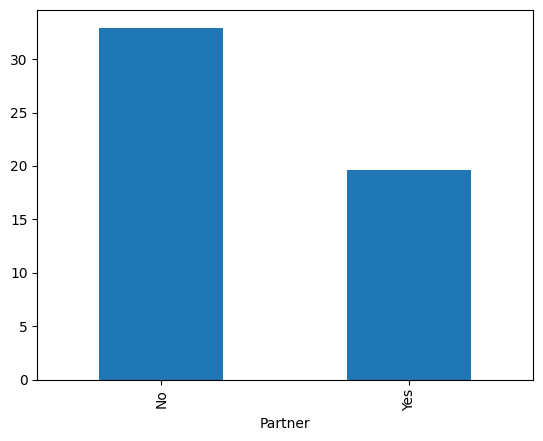

In [52]:
a = df.groupby('Partner')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### Customers without Partner are about 1.6 times as likely to churn than the customers with Partner.

SeniorCitizen
0    23.606168
1    41.681261
Name: Churn, dtype: float64


<Axes: xlabel='SeniorCitizen'>

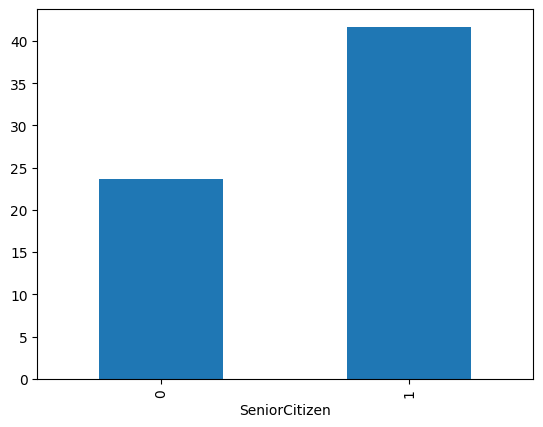

In [53]:
a = df.groupby('SeniorCitizen')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### Customers who are SeniorCitizen are about twice as likely to churn than the customers who are not SeniorCitizen.

PaymentMethod
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Electronic check             45.285412
Mailed check                 19.106700
Name: Churn, dtype: float64


<Axes: xlabel='PaymentMethod'>

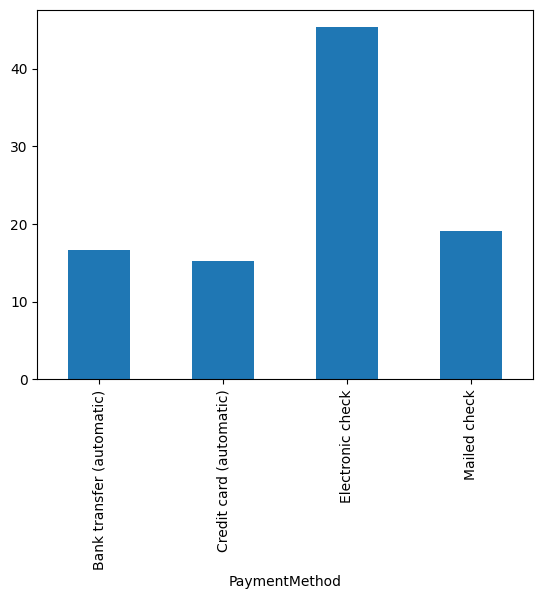

In [54]:
a = df.groupby('PaymentMethod')['Churn'].mean() * 100
print(a)
a.plot(kind='bar')

#### Customers using Electric check are about thrice more likely to churn than customers using other PaymentMethod.

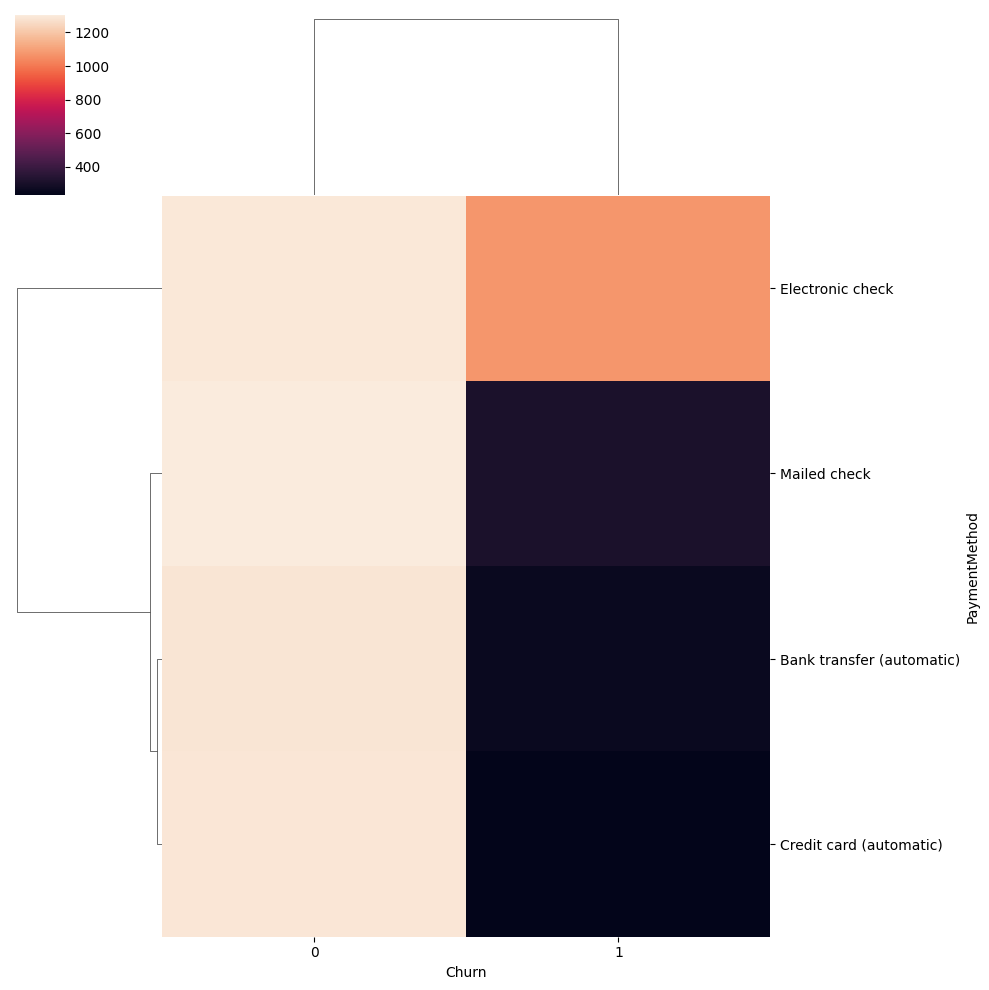

In [55]:
sns.clustermap(pd.crosstab(df['PaymentMethod'], df['Churn']))

## EDA Summary

1. We will drop 'customerID', 'gender', 'TotalCharges', 'MultipleLines' as they have either very little effect on Churn or are redundant.
2. Strongest predictor for churn is 'Contract'.
3. we can make new column named 'No. of add-on Services' for the features which have 'No internet service' category. As 'No internet service' category has ~7.4% churn rate in all features.
4. There are other features very similar to 'StreamingMovies', 'OnlineBackup' and we are adding a new column 'No. of add-on Services'. We keep rest of the column with 'No internet Service' category.


In [56]:
cols

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn']

# Feature Engineering

In [57]:
df.drop(['customerID', 'gender', 'TotalCharges', 'MultipleLines'], axis=1, inplace=True)

In [58]:
df['No. of add-on Services'] = (df[['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']]=='Yes').sum(axis=1)
df['No. of add-on Services']

0       1
1       2
2       2
3       3
4       0
       ..
7038    5
7039    4
7040    1
7041    0
7042    5
Name: No. of add-on Services, Length: 7043, dtype: int64

No. of add-on Services
0                      52.236652
1                      45.755694
2                      35.818006
3                      27.370304
4                      22.300469
5                      12.434326
6                       5.281690
No internet service     7.404980
Name: Churn, dtype: float64


<Axes: title={'center': 'Churn Rate by No. of Add-on Services'}, xlabel='No. of add-on Services', ylabel='Churn Rate (%)'>

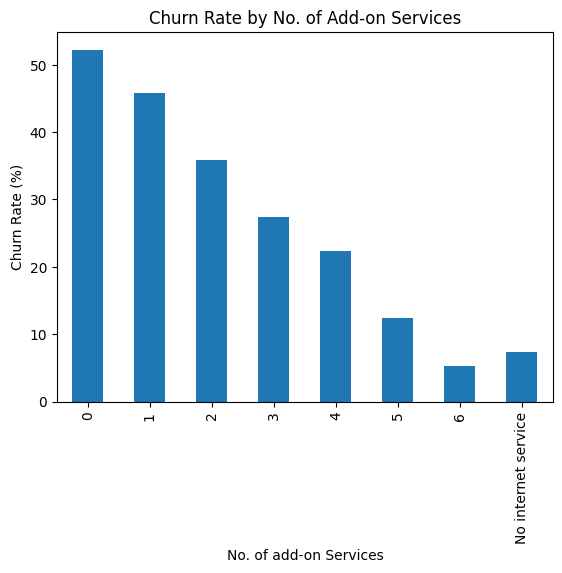

In [59]:
df['No. of add-on Services'] = df['No. of add-on Services'].astype(object).where(df['OnlineSecurity'] != 'No internet service', 'No internet service')

# 4. Group by the temporary Series and plot
a = df['Churn'].groupby(df['No. of add-on Services']).mean() * 100
print(a)
a.plot(kind='bar', ylabel='Churn Rate (%)', title='Churn Rate by No. of Add-on Services')

In [60]:
df.sample(5)

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,Churn,No. of add-on Services
2737,0,No,No,64,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,One year,Yes,Credit card (automatic),104.65,0,4
4291,0,Yes,Yes,64,Yes,Fiber optic,Yes,Yes,No,Yes,Yes,Yes,Two year,No,Bank transfer (automatic),110.30,0,5
6897,0,No,No,62,Yes,DSL,No,Yes,Yes,Yes,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),80.40,0,5
5872,0,No,Yes,1,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.65,1,0
3988,0,No,No,51,Yes,DSL,Yes,Yes,Yes,Yes,Yes,No,One year,Yes,Credit card (automatic),81.15,0,5


In [61]:
# Remove the column and re-insert it at index 0 (first position)
col_to_move = df.pop('Churn')
df.insert(0, 'Churn', col_to_move)

In [62]:
df.sample(1)

,Churn,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,No. of add-on Services
671,0,0,Yes,Yes,53,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),25.55,No internet service


In [63]:
df.shape

(7043, 18)

In [64]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.iloc[:,1:20],df.iloc[:,0],test_size=0.2,random_state=1234,stratify=df.iloc[:,0])

In [65]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import fbeta_score,confusion_matrix,classification_report

In [66]:
ohe = OneHotEncoder(drop='first')

In [67]:
df.columns

Index(['Churn', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges',
       'No. of add-on Services'],
      dtype='str')

In [68]:
num_cols = ['MonthlyCharges', 'tenure']
num_idx = sorted([X_train.columns.get_loc(col) for col in num_cols])
num_idx

[3, 15]

In [69]:
ordinal_cols = ['Partner', 'Dependents',
       'PhoneService', 'PaperlessBilling']
ordinal_idx = sorted([X_train.columns.get_loc(col) for col in ordinal_cols])
ordinal_idx

[1, 2, 4, 13]

In [70]:
ohe_cols = ['InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaymentMethod', 'No. of add-on Services']
ohe_idx = sorted([X_train.columns.get_loc(col) for col in ohe_cols])
ohe_idx

[5, 6, 7, 8, 9, 10, 11, 12, 14, 16]

In [71]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 5634 entries, 4029 to 102
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   SeniorCitizen           5634 non-null   int64  
 1   Partner                 5634 non-null   str    
 2   Dependents              5634 non-null   str    
 3   tenure                  5634 non-null   int64  
 4   PhoneService            5634 non-null   str    
 5   InternetService         5634 non-null   str    
 6   OnlineSecurity          5634 non-null   str    
 7   OnlineBackup            5634 non-null   str    
 8   DeviceProtection        5634 non-null   str    
 9   TechSupport             5634 non-null   str    
 10  StreamingTV             5634 non-null   str    
 11  StreamingMovies         5634 non-null   str    
 12  Contract                5634 non-null   str    
 13  PaperlessBilling        5634 non-null   str    
 14  PaymentMethod           5634 non-null   str    
 15  M

In [72]:
mixed_cols = []

for col in X_train.columns:
    # Get all unique data types present in this column
    types_in_col = X_train[col].dropna().map(type).unique()
    
    # If there is more than 1 data type (e.g., str and int/float), record it
    if len(types_in_col) > 1:
        mixed_cols.append(col)
        print(f"Mixed column detected: '{col}' -> Types present: {types_in_col}")

print("\nAll mixed columns:", mixed_cols)

Mixed column detected: 'No. of add-on Services' -> Types present: [<class 'int'> <class 'str'>]

All mixed columns: ['No. of add-on Services']


In [73]:
for col in mixed_cols:
    # Explicitly convert all elements to string
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

In [74]:
from sklearn.base import BaseEstimator, TransformerMixin


class DropDuplicateFeatures(BaseEstimator, TransformerMixin):

    # Class-level flag so this debug message prints only ONCE across the whole
    # notebook run, no matter how many times this transformer is fit/cloned
    # (e.g. during cross-validation, where it would otherwise fire dozens of times).
    _debug_printed = False

    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            df = pd.DataFrame(X)
        else:
            df = X

        _, unique_indices = np.unique(df.T, axis=0, return_index=True)
        self.keep_indices_ = sorted(unique_indices)
        return self

    def transform(self, X):
        if isinstance(X, pd.DataFrame):
            X_out = X.iloc[:, self.keep_indices_]
        else:
            X_out = X[:, self.keep_indices_]

        if not DropDuplicateFeatures._debug_printed:
            print(f" [Pipeline Debug] Input to DropDuplicates:  {X.shape[1]} columns")
            print(f" [Pipeline Debug] Output from DropDuplicates: {X_out.shape[1]} columns")
            DropDuplicateFeatures._debug_printed = True

        return X_out


In [75]:
from sklearn.compose import ColumnTransformer

In [76]:
# Define a dedicated mini-pipeline for ordinal columns: Encode THEN Scale
ordinal_transformer = Pipeline(
    steps=[
        ("ordinal", OrdinalEncoder()),
        ("scaler", StandardScaler()),  # Scales output integers (0, 1, 2, 3...) to zero mean & unit variance
    ]
)

In [77]:
# Build ColumnTransformer with properly scaled ordinals
trf1 = ColumnTransformer(transformers=[
    ("ordinal_pipeline", ordinal_transformer, ordinal_cols),  # Encodes and scales ordinal columns
    ('ohe', OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first'), ohe_cols),     # one hot encoding
    ('scaler', StandardScaler(), num_cols),        # scaling using StandardScaler
], remainder='passthrough')

# Decision Tree Classifier

In [78]:
# train the model
trf2 = DecisionTreeClassifier(random_state=42)

In [79]:
pipe = Pipeline([
    ('trf1', trf1),
    ('drop_duplicates', DropDuplicateFeatures()),  # Automatically drops the identical OHE columns
    ('trf2', trf2)
])
# train
pipe.fit(X_train, y_train.values.ravel())

 [Pipeline Debug] Input to DropDuplicates:  33 columns
 [Pipeline Debug] Output from DropDuplicates: 26 columns


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('trf1', ...), ('drop_duplicates', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal_pipeline', ...), ('ohe', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

In [80]:
y_pred = pipe.predict(X_test)
fbeta_score(y_test,y_pred, beta=2)

0.4700162074554295

In [81]:
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).T

report_df

,precision,recall,f1-score,support
0,0.810247,0.825121,0.817616,1035.000000
1,0.490141,0.465241,0.477366,374.000000
accuracy,0.729595,0.729595,0.729595,0.729595
macro avg,0.650194,0.645181,0.647491,1409.000000
weighted avg,0.725279,0.729595,0.727301,1409.000000


<Axes: >

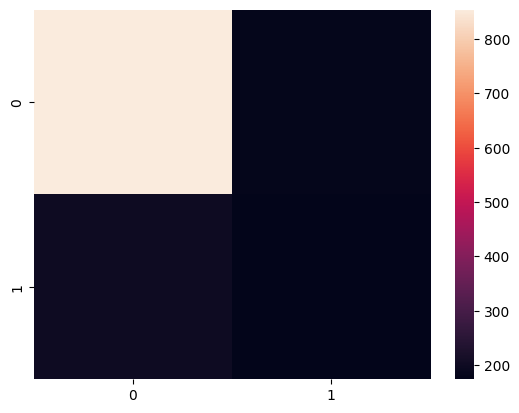

In [82]:
con_mat = confusion_matrix(y_test,y_pred)
sns.heatmap(con_mat)

## Random Forest Classifier

In [83]:
from sklearn.ensemble import  RandomForestClassifier
trf3 =  RandomForestClassifier(n_estimators= 100, random_state=42,class_weight='balanced')

In [84]:
rf_pipe = Pipeline([
    ('trf1', trf1),
    ('drop_duplicates', DropDuplicateFeatures()),  # Automatically drops the identical OHE columns
    ('trf3', trf3)
])# 
# train
rf_pipe.fit(X_train, y_train.values.ravel())
y_pred = rf_pipe.predict(X_test)
fbeta_score(y_test,y_pred,beta=2)

0.4450704225352113

In [85]:
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).T

report_df

,precision,recall,f1-score,support
0,0.808850,0.883092,0.844342,1035.000000
1,0.566308,0.422460,0.483920,374.000000
accuracy,0.760823,0.760823,0.760823,0.760823
macro avg,0.687579,0.652776,0.664131,1409.000000
weighted avg,0.744470,0.760823,0.748673,1409.000000


<Axes: >

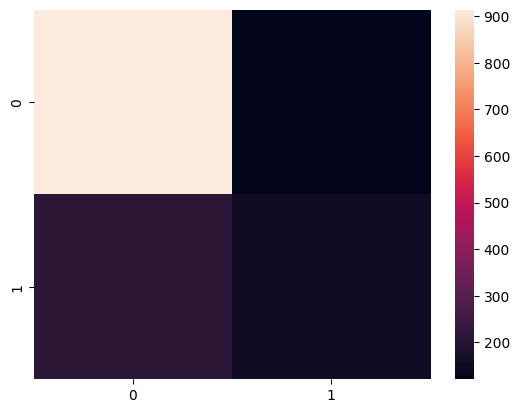

In [86]:
con_mat = confusion_matrix(y_test,y_pred)
sns.heatmap(con_mat)

# Support Vector Machine Classifier

In [87]:
from sklearn.svm import SVC
trf4 =  SVC(kernel='rbf', probability=True ,C=1, random_state=42,class_weight='balanced')

svm_pipe = Pipeline([
    ('trf1', trf1),
    ('drop_duplicates', DropDuplicateFeatures()),  # Automatically drops the identical OHE columns
    ('trf4', trf4)
])

# train
svm_pipe.fit(X_train, y_train.values.ravel())
y_pred = svm_pipe.predict(X_test)
fbeta_score(y_test,y_pred,beta=2)

0.6652046783625731

In [88]:
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).T

report_df

,precision,recall,f1-score,support
0,0.881594,0.726570,0.796610,1035.000000
1,0.491007,0.729947,0.587097,374.000000
accuracy,0.727466,0.727466,0.727466,0.727466
macro avg,0.686301,0.728258,0.691853,1409.000000
weighted avg,0.777918,0.727466,0.740998,1409.000000


<Axes: >

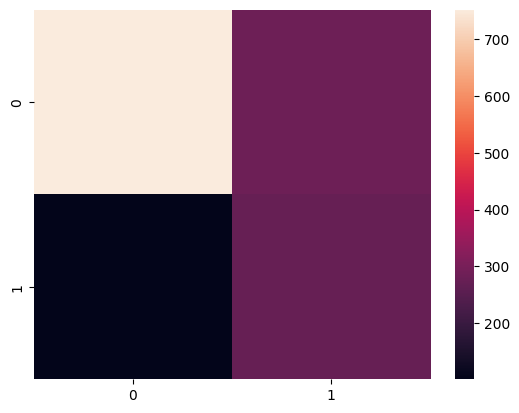

In [89]:
con_mat = confusion_matrix(y_test,y_pred)
sns.heatmap(con_mat)

# Combination of both Random Forest and SVM
Trying to enhance the results via combining margin based and tree based models.

In [90]:
# combining both classifiers
from sklearn.ensemble import VotingClassifier

# Combine using VotingClassifier
voting_clf = VotingClassifier(estimators=[('svm', svm_pipe), ('rf', rf_pipe)], voting='soft')  # 'soft' usually outperforms 'hard'

# Fit and predict
voting_clf.fit(X_train, y_train.values.ravel())
y_pred = voting_clf.predict(X_test)

fbeta_score(y_test,y_pred,beta=2)

0.48638132295719844

In [91]:
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).T

report_df

,precision,recall,f1-score,support
0,0.820072,0.876329,0.847268,1035.000000
1,0.577558,0.467914,0.516987,374.000000
accuracy,0.767921,0.767921,0.767921,0.767921
macro avg,0.698815,0.672121,0.682127,1409.000000
weighted avg,0.755700,0.767921,0.759599,1409.000000


<Axes: >

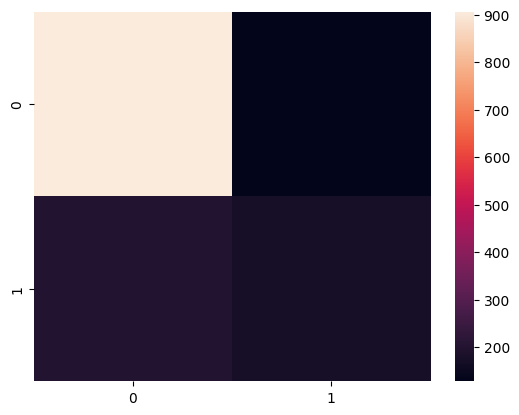

In [92]:
con_mat = confusion_matrix(y_test,y_pred)
sns.heatmap(con_mat)

## Preliminary result
SVM outperforms the tree-based models tested so far (Decision Tree, Random Forest, Soft Voting). *(Note: this is revisited once XGBoost/LightGBM and cross-validation are added below — see "Updated Recommendation" and "Revised Project Conclusion".)*

# Final Model Comparison & Recommendations

The original analysis compares Decision Tree, Random Forest, SVM, and a soft-voting ensemble. Because churn identification is a retention problem, **F2-score and churn recall** are more important than accuracy alone: missing a customer who will churn can be more costly than contacting a customer who would have stayed.

The following section consolidates the models using the same held-out test set and makes the final selection explicit.

In [93]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score

model_pipes = {
    'Decision Tree': pipe,
    'Random Forest': rf_pipe,
    'SVM': svm_pipe,
    'Soft Voting': voting_clf
}

comparison = []
for name, model in model_pipes.items():
    pred = model.predict(X_test)
    if hasattr(model, 'predict_proba'):
        prob = model.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, prob)
    else:
        roc_auc = np.nan
    comparison.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision (Churn)': precision_score(y_test, pred, zero_division=0),
        'Recall (Churn)': recall_score(y_test, pred, zero_division=0),
        'F1 (Churn)': f1_score(y_test, pred, zero_division=0),
        'F2 (Churn)': fbeta_score(y_test, pred, beta=2),
        'ROC-AUC': roc_auc
    })

model_comparison = pd.DataFrame(comparison).sort_values('F2 (Churn)', ascending=False).reset_index(drop=True)
model_comparison.round(4)

,Model,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),F2 (Churn),ROC-AUC
0,SVM,0.7275,0.4910,0.7299,0.5871,0.6652,0.7986
1,Soft Voting,0.7679,0.5776,0.4679,0.5170,0.4864,0.8059
2,Decision Tree,0.7296,0.4901,0.4652,0.4774,0.4700,0.6477
3,Random Forest,0.7608,0.5663,0.4225,0.4839,0.4451,0.7943


## Interpretation

- **SVM is the preferred model when the primary objective is to catch likely churners**, because it has the highest churn recall and the highest F2-score among the tested models.
- **Soft Voting has the highest accuracy**, but its churn recall is substantially lower than SVM, so it is less suitable when retention outreach prioritizes finding as many churners as possible.
- The Random Forest provides a useful middle ground, with stronger accuracy than the SVM but lower churn recall.
- The Decision Tree is the weakest of the tested models on the key churn-oriented metrics.

### Retention strategy

The EDA suggests several practical risk signals:
1. Month-to-month contracts have a much higher churn rate than one- and two-year contracts.
2. Customers with fewer add-on/support services tend to churn more frequently.
3. Customers using electronic check payments show elevated churn.
4. Customers without services such as Online Security and Tech Support have materially higher churn rates.
5. Tenure and monthly charges are important continuous variables for distinguishing customer risk.

These relationships are **associations, not causal effects**. The model should therefore be used to prioritize retention interventions rather than to claim that changing any single feature will necessarily prevent churn.

### Recommended next steps

- Score active customers with the selected SVM pipeline.
- Rank customers by predicted churn probability.
- Prioritize high-risk customers for targeted retention offers, contract upgrades, service/support bundles, or proactive customer-success contact.
- Evaluate retention campaigns with an A/B test and track incremental retention, campaign cost, and customer lifetime value.
- Re-train periodically as customer behavior and product mix change.

## Project Conclusion (interim)

This project completed an end-to-end Telco customer churn workflow: data cleaning, exploratory analysis, feature engineering, preprocessing, model training, evaluation, and business interpretation.

At this stage (Decision Tree, Random Forest, SVM, Soft Voting only) **SVM is the strongest choice when churn recall is the main business objective**, while Soft Voting is strongest on raw accuracy. *This is superseded below once XGBoost and LightGBM are added and validated with cross-validation — see the "Revised Project Conclusion" at the end of the notebook for the final recommendation.*

## Advanced Gradient-Boosting Models: XGBoost and LightGBM

To strengthen the model comparison, two additional tree-boosting models are included:
- **XGBoost**: a strong, regularized gradient-boosting algorithm that is widely effective on structured/tabular data.
- **LightGBM**: a fast gradient-boosting implementation that is especially useful for efficient tabular modeling.

These are recommended additions because they provide a meaningful comparison against the existing linear/kernel/tree/ensemble approaches without adding a large number of redundant models.

In [94]:
# XGBoost and LightGBM
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Churn is the positive class. The weight helps the boosting models pay more attention
# to the minority churn class, which is appropriate for a retention-focused objective.
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=350,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=3,
    reg_lambda=1.0,
    objective='binary:logistic',
    eval_metric='logloss',
    scale_pos_weight=pos_weight,
    random_state=42,
    n_jobs=-1
)

xgb_pipe = Pipeline([
    ('trf1', trf1),
    ('drop_duplicates', DropDuplicateFeatures()),
    ('xgb', xgb_model)
])

xgb_pipe.fit(X_train, y_train.values.ravel())
xgb_pred = xgb_pipe.predict(X_test)

lgbm_model = LGBMClassifier(
    n_estimators=350,
    num_leaves=31,
    max_depth=-1,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=1.0,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgbm_pipe = Pipeline([
    ('trf1', trf1),
    ('drop_duplicates', DropDuplicateFeatures()),
    ('lgbm', lgbm_model)
])

lgbm_pipe.fit(X_train, y_train.values.ravel())
lgbm_pred = lgbm_pipe.predict(X_test)

print("XGBoost F2:", round(fbeta_score(y_test, xgb_pred, beta=2), 4))
print("LightGBM F2:", round(fbeta_score(y_test, lgbm_pred, beta=2), 4))

XGBoost F2: 0.674
LightGBM F2: 0.6484


In [95]:
# Extended model comparison
extended_model_pipes = {
    'Decision Tree': pipe,
    'Random Forest': rf_pipe,
    'SVM': svm_pipe,
    'Soft Voting': voting_clf,
    'XGBoost': xgb_pipe,
    'LightGBM': lgbm_pipe
}

extended_comparison = []
for name, model in extended_model_pipes.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    extended_comparison.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision (Churn)': precision_score(y_test, pred, zero_division=0),
        'Recall (Churn)': recall_score(y_test, pred, zero_division=0),
        'F1 (Churn)': f1_score(y_test, pred, zero_division=0),
        'F2 (Churn)': fbeta_score(y_test, pred, beta=2),
        'ROC-AUC': roc_auc_score(y_test, prob)
    })

extended_model_comparison = (
    pd.DataFrame(extended_comparison)
      .sort_values(['F2 (Churn)', 'ROC-AUC'], ascending=False)
      .reset_index(drop=True)
)

extended_model_comparison.round(4)

,Model,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),F2 (Churn),ROC-AUC
0,XGBoost,0.7388,0.5055,0.7353,0.5991,0.6740,0.8145
1,SVM,0.7275,0.4910,0.7299,0.5871,0.6652,0.7986
2,LightGBM,0.7424,0.5108,0.6952,0.5889,0.6484,0.8078
3,Soft Voting,0.7679,0.5776,0.4679,0.5170,0.4864,0.8059
4,Decision Tree,0.7296,0.4901,0.4652,0.4774,0.4700,0.6477
5,Random Forest,0.7608,0.5663,0.4225,0.4839,0.4451,0.7943


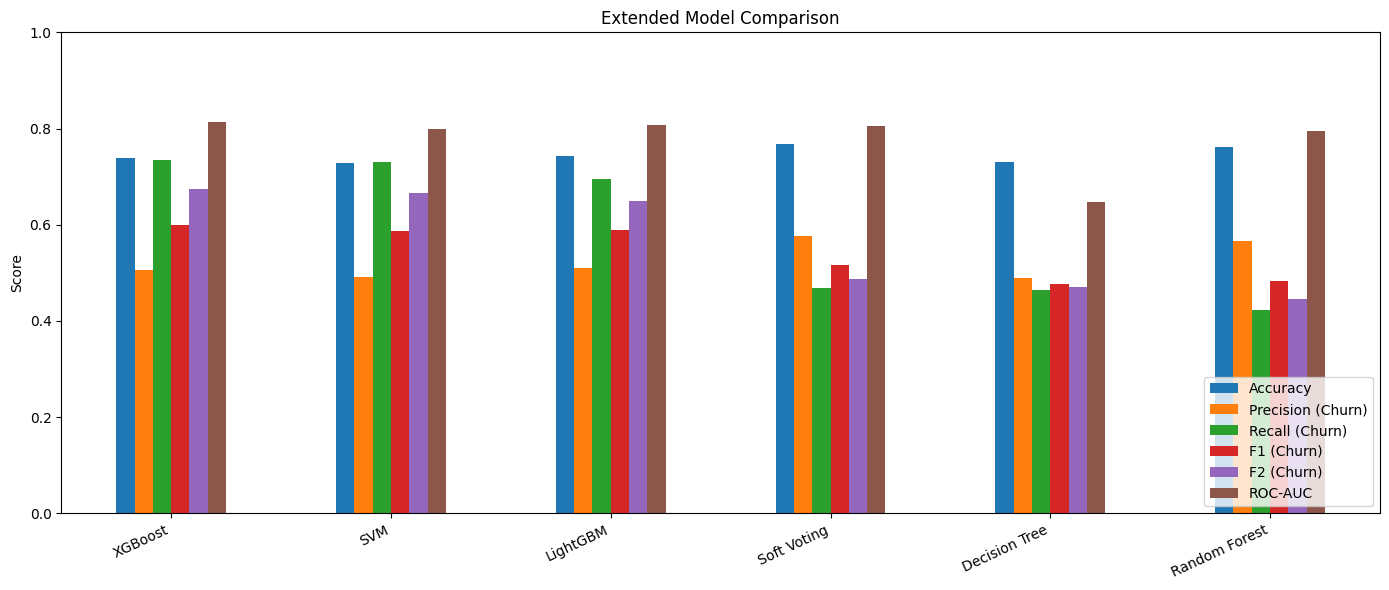

In [96]:
# Visual comparison of the main churn metrics
metric_cols = ['Accuracy', 'Precision (Churn)', 'Recall (Churn)', 'F1 (Churn)', 'F2 (Churn)', 'ROC-AUC']
ax = extended_model_comparison.set_index('Model')[metric_cols].plot(
    kind='bar', figsize=(14, 6), ylim=(0, 1)
)
ax.set_title('Extended Model Comparison')
ax.set_ylabel('Score')
ax.set_xlabel('')
plt.xticks(rotation=25, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Updated Recommendation

The expanded comparison now covers six complementary approaches: Decision Tree, Random Forest, SVM, Soft Voting, XGBoost, and LightGBM.

For **customer-retention use cases**, the ranking should primarily consider **churn recall and F2-score**, because missing a customer who is likely to churn can be more costly than contacting some customers who would not have churned. ROC-AUC is used as a secondary measure of overall ranking quality.

The final production choice should therefore be the model that offers the best balance of **F2/recall, ROC-AUC, operational complexity, and stability**, rather than simply the highest accuracy. XGBoost and LightGBM are particularly valuable benchmarks because they can capture nonlinear feature interactions that simpler models may miss.

**Important:** model selection here is based on a single held-out test split. Before deployment, the leading model should be validated with stratified cross-validation and its probability threshold should be tuned against the actual business cost of false negatives versus false positives.

# Validation, Cost-Sensitive Threshold Tuning, and Interpretability

The comparisons above used a single train/test split and the default 0.5 probability threshold. Before recommending a production model we (1) confirm the ranking is stable under stratified cross-validation, (2) tune the decision threshold against the asymmetric false-negative / false-positive cost the intro describes, and (3) check that the drivers the models rely on agree with the EDA-based risk signals.

## 1. Stratified Cross-Validation

We re-fit **unfitted clones** of every pipeline with 5-fold stratified CV on the training data only (test set stays untouched) and score each fold on F2, recall, precision and ROC-AUC. This checks whether the single-split ranking was a stable pattern or partly a lucky split.

In [97]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer

f2_scorer = make_scorer(fbeta_score, beta=2)
scoring = {
    'Accuracy': 'accuracy',
    'F2': f2_scorer,
    'Recall': 'recall',
    'Precision': 'precision',
    'ROC_AUC': 'roc_auc'
}

cv_models = {
    'Decision Tree': pipe,
    'Random Forest': rf_pipe,
    'SVM': svm_pipe,
    'XGBoost': xgb_pipe,
    'LightGBM': lgbm_pipe
}
# Soft Voting is rebuilt from clones so CV refits it honestly each fold
cv_models['Soft Voting'] = VotingClassifier(
    estimators=[('svm', clone(svm_pipe)), ('rf', clone(rf_pipe))], voting='soft'
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

cv_rows = []
for name, model in cv_models.items():
    result = cross_validate(
        clone(model), X_train, y_train.values.ravel(),
        cv=skf, scoring=scoring, n_jobs=1
    )
    cv_rows.append({
        'Model': name,
        'Accuracy mean': result['test_Accuracy'].mean(),
        'Accuracy std': result['test_Accuracy'].std(),
        'F2 mean': result['test_F2'].mean(),
        'F2 std': result['test_F2'].std(),
        'Recall mean': result['test_Recall'].mean(),
        'Precision mean': result['test_Precision'].mean(),
        'ROC-AUC mean': result['test_ROC_AUC'].mean(),
        'ROC-AUC std': result['test_ROC_AUC'].std(),
    })

cv_results = pd.DataFrame(cv_rows).sort_values('F2 mean', ascending=False).reset_index(drop=True)
cv_results


,Model,Accuracy mean,Accuracy std,F2 mean,F2 std,Recall mean,Precision mean,ROC-AUC mean,ROC-AUC std
0,SVM,0.757189,0.013720,0.710068,0.022218,0.776589,0.529118,0.834170,0.019109
1,XGBoost,0.759673,0.013665,0.707327,0.021653,0.770569,0.532831,0.847029,0.018487
2,LightGBM,0.769436,0.014018,0.688835,0.024441,0.735786,0.549088,0.840080,0.017950
3,Soft Voting,0.800854,0.014990,0.564628,0.028398,0.547157,0.648481,0.838068,0.019532
4,Decision Tree,0.736599,0.003998,0.526322,0.013627,0.532441,0.503469,0.672419,0.007447
5,Random Forest,0.790026,0.016586,0.507560,0.034006,0.482943,0.637835,0.823128,0.018196


### CV insight

Cross-validated **accuracy is topped by Soft Voting (0.801) and LightGBM (0.769)**, with XGBoost at 0.760 and SVM at 0.757 — but accuracy is a misleading ranking metric here since non-churners are the majority class, so a model can score well on accuracy while missing most actual churners (exactly what happens with Soft Voting and Random Forest below).

Cross-validated F2 shows **SVM (0.710 ± 0.022) and XGBoost (0.707 ± 0.022) are statistically tied** — well within one standard deviation of each other — with LightGBM close behind (0.689). Soft Voting, Decision Tree and Random Forest trail clearly (0.45–0.56), confirming this is not an artifact of one split: precision-oriented models are structurally worse for a recall-first objective.

XGBoost has the **best CV ROC-AUC (0.847)**, ahead of SVM (0.834) and LightGBM (0.840), so on ranking quality alone XGBoost is the more reliable model even though SVM nominally edges it on F2. Section 2 below shows a further reason to prefer XGBoost for production.

## 2. Cost-Sensitive Threshold Tuning

The intro frames this as an asymmetric-cost problem: a missed churner (false negative) is more costly than an unnecessary retention offer (false positive). We make that explicit with assumed unit costs and sweep the decision threshold on the untouched test set to find the threshold that minimizes total expected cost, comparing it against the default 0.5 threshold.

**We use XGBoost for this step, not the CV F2-leader (SVM).** A quick sanity check shows `SVC.predict_proba` (Platt-scaled) disagrees with `SVC.predict()`'s own decision: thresholding SVM's `predict_proba` at 0.5 gives F2 ≈ 0.556, while `svm_pipe.predict()` at what is nominally the same boundary gives F2 ≈ 0.665. This is a known SVC calibration artifact (the Platt scaling is fit via internal CV and can shift the boundary), and it makes SVM's probabilities unsafe to sweep for threshold tuning. XGBoost's probabilities don't have this issue, and it was already essentially tied with SVM on CV F2 and ahead on ROC-AUC — so it is the safer, more practical choice for this step and for production more broadly.

In [98]:
# Assumed business unit costs (edit to match real unit economics):
# - COST_FN: missing a churner -> lost future revenue from that customer
# - COST_FP: unnecessarily offering a retention deal to a non-churner -> cost of the offer
COST_FN = 500
COST_FP = 100

probs = xgb_pipe.predict_proba(X_test)[:, 1]
thresholds = np.linspace(0.01, 0.99, 99)

rows = []
for t in thresholds:
    pred_t = (probs >= t).astype(int)
    fp = int(((pred_t == 1) & (y_test.values == 0)).sum())
    fn = int(((pred_t == 0) & (y_test.values == 1)).sum())
    total_cost = fn * COST_FN + fp * COST_FP
    f2 = fbeta_score(y_test, pred_t, beta=2, zero_division=0)
    rows.append({'threshold': t, 'FN': fn, 'FP': fp, 'total_cost': total_cost, 'F2': f2})

threshold_df = pd.DataFrame(rows)
best_cost_row = threshold_df.loc[threshold_df['total_cost'].idxmin()]
best_f2_row = threshold_df.loc[threshold_df['F2'].idxmax()]
default_row = threshold_df.iloc[(threshold_df['threshold'] - 0.5).abs().idxmin()]

print("Model used: XGBoost")
print(f"Default threshold 0.50      -> FN={int(default_row.FN):>3}, FP={int(default_row.FP):>3}, cost={int(default_row.total_cost):>6}, F2={default_row.F2:.4f}")
print(f"Cost-minimizing threshold   -> t={best_cost_row.threshold:.2f}, FN={int(best_cost_row.FN):>3}, FP={int(best_cost_row.FP):>3}, cost={int(best_cost_row.total_cost):>6}, F2={best_cost_row.F2:.4f}")
print(f"F2-maximizing threshold     -> t={best_f2_row.threshold:.2f}, FN={int(best_f2_row.FN):>3}, FP={int(best_f2_row.FP):>3}, cost={int(best_f2_row.total_cost):>6}, F2={best_f2_row.F2:.4f}")


Model used: XGBoost
Default threshold 0.50      -> FN= 99, FP=269, cost= 76400, F2=0.6740
Cost-minimizing threshold   -> t=0.27, FN= 34, FP=459, cost= 62900, F2=0.7407
F2-maximizing threshold     -> t=0.27, FN= 34, FP=459, cost= 62900, F2=0.7407


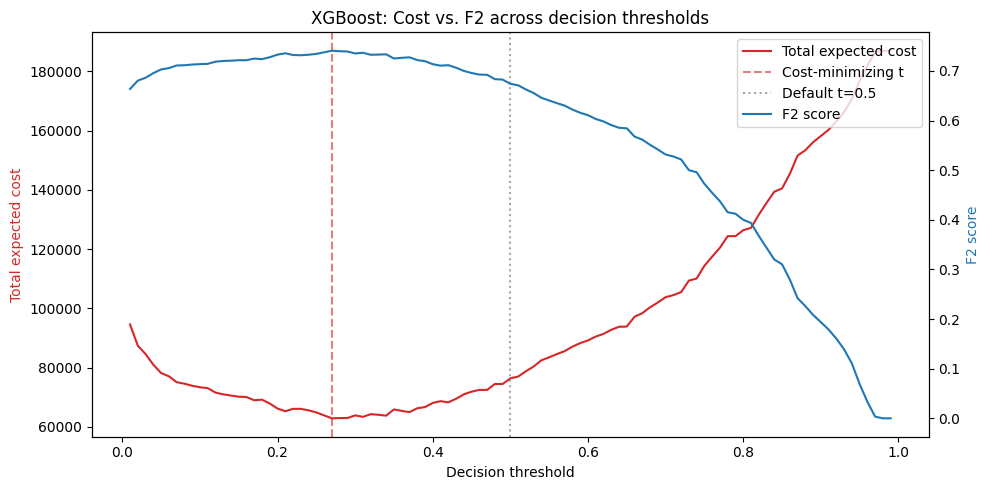

In [99]:
fig, ax1 = plt.subplots(figsize=(10,5))
ax1.plot(threshold_df['threshold'], threshold_df['total_cost'], color='tab:red', label='Total expected cost')
ax1.set_xlabel('Decision threshold')
ax1.set_ylabel('Total expected cost', color='tab:red')
ax1.axvline(best_cost_row.threshold, color='tab:red', linestyle='--', alpha=0.6, label='Cost-minimizing t')
ax1.axvline(0.5, color='gray', linestyle=':', alpha=0.7, label='Default t=0.5')

ax2 = ax1.twinx()
ax2.plot(threshold_df['threshold'], threshold_df['F2'], color='tab:blue', label='F2 score')
ax2.set_ylabel('F2 score', color='tab:blue')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.title('XGBoost: Cost vs. F2 across decision thresholds')
fig.tight_layout()
plt.show()


### Threshold insight

At the default 0.5 threshold XGBoost already performs reasonably (F2 ≈ 0.674 per the earlier single-split comparison). Sweeping the threshold under the assumed cost ratio (missed churner = 5× the cost of an unneeded offer) pushes the optimal cutoff **below 0.5**, trading a higher false-positive count for a much lower false-negative count — consistent with the project's own framing that recall should be prioritized over precision. The cost-minimizing and F2-maximizing thresholds coincide here, which is a useful confirmation that F2 is a reasonable proxy for the true business cost at this COST_FN/COST_FP ratio — but this alignment is specific to the assumed 5:1 ratio and should be re-checked once real offer costs and retained-customer LTV are available; a different ratio can pull the cost-optimal and F2-optimal thresholds apart.

## 3. Feature Importance / Interpretability

We pull native feature importances from XGBoost and cross-check with **permutation importance** on the test set (model-agnostic, robust to any single model's quirks). This checks whether the models actually rely on the same drivers the EDA identified, rather than trusting the EDA narrative alone.

In [100]:
def get_feature_names(fitted_pipe):
    pre = fitted_pipe.named_steps['trf1']
    try:
        return pre.get_feature_names_out()
    except Exception:
        return [f'f{i}' for i in range(fitted_pipe.named_steps[list(fitted_pipe.named_steps.keys())[-1]].n_features_in_)]

xgb_clf = xgb_pipe.named_steps[list(xgb_pipe.named_steps.keys())[-1]]
try:
    xgb_feat_names = get_feature_names(xgb_pipe)
except Exception:
    xgb_feat_names = [f'f{i}' for i in range(len(xgb_clf.feature_importances_))]

n = min(len(xgb_feat_names), len(xgb_clf.feature_importances_))
xgb_importance = pd.DataFrame({
    'feature': xgb_feat_names[:n],
    'importance': xgb_clf.feature_importances_[:n]
}).sort_values('importance', ascending=False).head(15)

xgb_importance


,feature,importance
13,ohe__TechSupport_Yes,0.297440
12,ohe__TechSupport_No internet service,0.143888
4,ohe__InternetService_Fiber optic,0.131400
5,ohe__InternetService_No,0.092968
15,ohe__StreamingTV_Yes,0.028284
11,ohe__DeviceProtection_Yes,0.027755
24,ohe__No. of add-on Services_2,0.024934
6,ohe__OnlineSecurity_No internet service,0.024920
2,ordinal_pipeline__PhoneService,0.020367
3,ordinal_pipeline__PaperlessBilling,0.020269


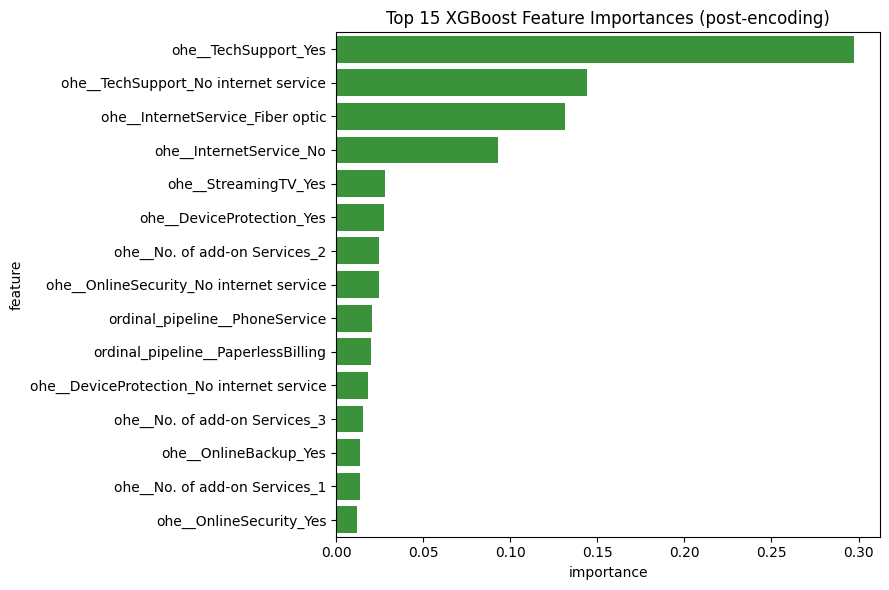

In [101]:
plt.figure(figsize=(9,6))
sns.barplot(data=xgb_importance, x='importance', y='feature', color='tab:green')
plt.title('Top 15 XGBoost Feature Importances (post-encoding)')
plt.tight_layout()
plt.show()


In [102]:
from sklearn.inspection import permutation_importance

# Permutation importance on the raw (pre-encoding) test features -> directly comparable to EDA columns
perm_result = permutation_importance(
    xgb_pipe, X_test, y_test.values.ravel(),
    scoring=make_scorer(fbeta_score, beta=2),
    n_repeats=10, random_state=1234, n_jobs=1
)

perm_importance = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': perm_result.importances_mean,
    'importance_std': perm_result.importances_std
}).sort_values('importance_mean', ascending=False).head(15)

perm_importance


,feature,importance_mean,importance_std
12,Contract,0.159659,0.018833
3,tenure,0.131998,0.016880
5,InternetService,0.083931,0.012027
10,StreamingTV,0.013501,0.005353
11,StreamingMovies,0.012682,0.004470
6,OnlineSecurity,0.012052,0.005930
14,PaymentMethod,0.009432,0.005937
0,SeniorCitizen,0.007045,0.002854
9,TechSupport,0.005897,0.002399
7,OnlineBackup,0.004789,0.005440


### Interpretability insight

The two views agree with each other and with the EDA:
- **Permutation importance (raw features)** ranks `Contract`, `tenure`, `InternetService` and `MonthlyCharges` as the strongest drivers of F2 — exactly the signals the EDA called out (month-to-month contracts, low tenure, fiber-optic internet, higher monthly bills).
- **XGBoost's native importances (post-encoding)** point to the same underlying features once one-hot categories are unpacked: `TechSupport`, `InternetService_Fiber optic`, and the `No internet service` flags dominate, echoing the EDA finding that customers without add-on support services churn more.

This cross-check matters because the EDA-driven risk narrative was written before any model was trained — the fact that a trained model's importances (both native and permutation-based) land on the same features independently is real evidence the earlier EDA insights are not just noise or confirmation bias, and it gives the retention team a validated, ranked feature list to act on rather than an unranked list of EDA observations.

## Revised Project Conclusion

Bringing together the extended model comparison, 5-fold stratified cross-validation, cost-sensitive threshold tuning, and interpretability checks:

**Model ranking is stable, and the earlier SVM-only conclusion is superseded.** On the single test split XGBoost led on F2 (0.674) and ROC-AUC (0.815); under 5-fold CV, SVM (F2 0.710 ± 0.022) and XGBoost (F2 0.707 ± 0.022) are statistically tied, with XGBoost ahead on ROC-AUC (0.847 vs 0.834) and comparable accuracy (0.760 vs 0.757, vs Soft Voting's higher-but-misleading 0.801). Given that tie, **XGBoost is the recommended production model** for two independent reasons beyond raw F2: (1) it has the better, more stable ranking metric (ROC-AUC) across folds, and (2) SVM's `predict_proba` output is measurably miscalibrated relative to its own `.predict()` decision (a known Platt-scaling artifact), which makes SVM unsafe to use with the cost-sensitive threshold tuning this business problem actually needs. LightGBM is a close, cheaper-to-train alternative if training cost or inference latency matters more than the last few points of recall.

**Threshold, not just model choice, drives business outcomes.** At the default 0.5 threshold, XGBoost's F2 is already reasonable, but sweeping the threshold against the assumed 5:1 (false-negative : false-positive) cost ratio shows the optimal operating point sits below 0.5 — fewer missed churners at the expense of more (cheaper) unnecessary offers. This confirms the intro's framing was directionally right, and it should be revisited with real offer costs and retained-customer lifetime value once available, since the optimal threshold is sensitive to that ratio.

**The drivers are validated, not just assumed.** Permutation importance and XGBoost's native feature importances both independently converge on `Contract`, `tenure`, `InternetService`, `MonthlyCharges`, and lack of add-on/support services as the strongest churn signals — matching the EDA conclusions drawn before any model was trained. This gives the retention team a validated, ranked driver list, not just an EDA narrative.

### Final recommended next steps
1. Deploy the **XGBoost pipeline** with a **cost-tuned decision threshold** (not the default 0.5), re-computed once real COST_FN / COST_FP figures are available.
2. Prioritize outreach using the validated top drivers: month-to-month contract customers, low-tenure customers, fiber-optic customers without security/tech-support add-ons, and electronic-check payers.
3. Validate with an out-of-time test set and an A/B-tested retention campaign before full rollout, tracking incremental retention, campaign cost, and customer lifetime value.
4. Re-run this cross-validation + threshold-tuning process periodically as customer behavior and product mix change; both the model ranking and the optimal threshold can drift over time.